# Project 2: Deep Learning Applications (Lab 5)
## Neural Networks, Convolutions, and Transfer Learning

## * **Student Name:** Haider Ali Asghar
* **Program:** Bachelor of Science in Electronics (BS 7th Semester)
* **Department:** Department of Electronics
* **Institution:** Quaid-i-Azam University
* **Course:** Introduction to Applied AI
* **Instructor:** Dr. Faiz Ahmad
* **Platform:** Kaggle Notebook (GPU T4 Enabled)

### Task 1.1: Imports, GPU check, and class counts

In [3]:
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device) # Must say cuda!

ROOT = '/kaggle/input/datasets/puneet6060/intel-image-classification'
TRAIN_DIR = f'{ROOT}/seg_train/seg_train'
TEST_DIR = f'{ROOT}/seg_test/seg_test'

classes = sorted(os.listdir(TRAIN_DIR))
for c in classes:
    n_tr = len(os.listdir(os.path.join(TRAIN_DIR, c)))
    n_te = len(os.listdir(os.path.join(TEST_DIR, c)))
    print(f'{c:10s} train {n_tr:5d} | test {n_te:4d}')

Device: cuda
buildings  train  2191 | test  437
forest     train  2271 | test  474
glacier    train  2404 | test  553
mountain   train  2512 | test  525
sea        train  2274 | test  510
street     train  2382 | test  501


### Task 1.2: Look at the images, then at the numbers

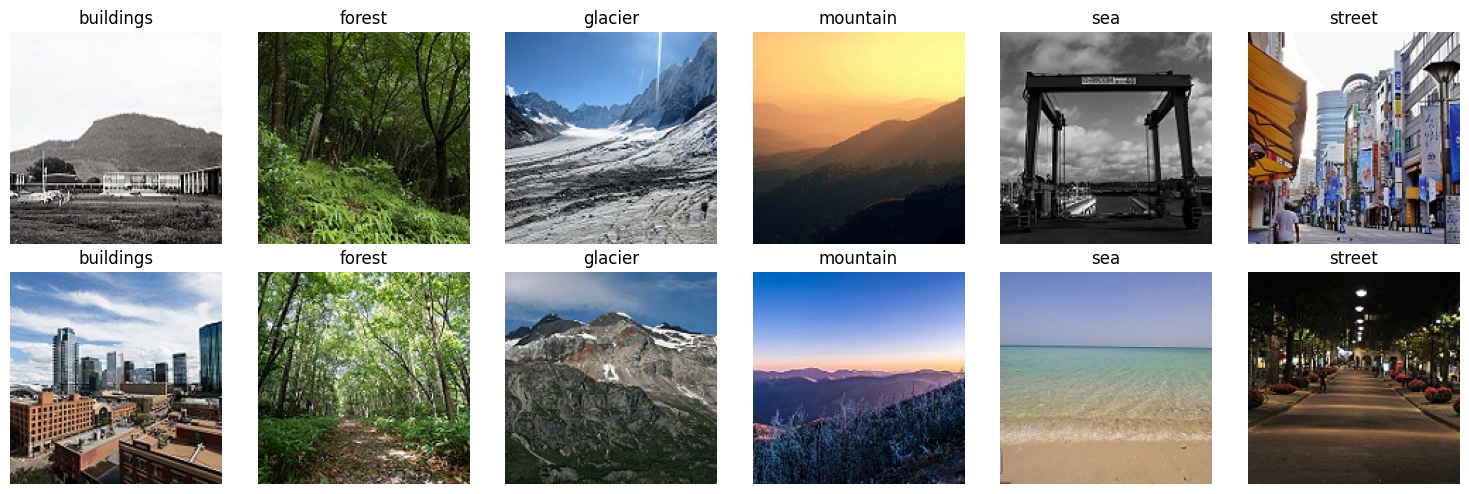

Shape (H, W, C): (150, 150, 3) dtype: uint8 range: 0 to 255
Top-left 3x3 of the red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [4]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, c in enumerate(classes):
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]
    for i, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(c)
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

arr = np.array(img)
print('Shape (H, W, C):', arr.shape, 'dtype:', arr.dtype, 'range:', arr.min(), 'to', arr.max())
print('Top-left 3x3 of the red channel:\n', arr[:3, :3, 0])

### **Write it: Image Observations & Predictions**

* **Visual Similarity:** The classes **Glacier** and **Mountain** look most similar by eye due to their shared icy and rocky textures.
* **Predicted Confusion Pair:** I predict the model will most frequently confuse **Glacier** with **Mountain**.
* **Image Properties:**
  * **Shape (H, W, C):** `(150, 150, 3)`
  * **Data Type (`dtype`):** `uint8`
  * **Value Range:** `0 to 255`

## Part 2: Convolution and Parameters by Hand 

### Task 2.1: Reproduce the lecture's convolution

tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


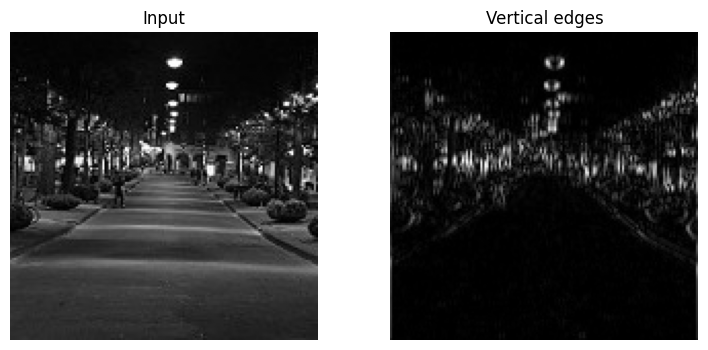

In [5]:
# The 5x5 example from the lecture: a vertical edge
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)
out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print(out.squeeze())
# expect three rows of [30, 30, 0]

# The same kernel on a real photo, converted to grayscale
g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')
ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')
for a in ax:
    a.axis('off')
plt.show()

### Task 2.2: Why convolutions, in numbers

In [6]:
def count(m):
    return sum(p.numel() for p in m.parameters())

conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
dense = nn.Linear(150 * 150 * 3, 512)

print(f'Conv 3x3, 3->64: {count(conv):,} parameters') # (3*3*3+1)*64
print(f'Dense 67,500->512: {count(dense):,} parameters')

t = torch.randn(1, 3, 224, 224)
for stride in [1, 2]:
    c = nn.Conv2d(3, 64, kernel_size=3, stride=stride, padding=1)
    print(f'stride {stride}: output {tuple(c(t).shape)}') # (W-K+2P)/S+1

print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))

Conv 3x3, 3->64: 1,792 parameters
Dense 67,500->512: 34,560,512 parameters
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)


### **Write it: Convolution & Dense Layer Parameters Arithmetic**

* **Arithmetic for Conv Layer ($1,792$ parameters):**
  Using the formula $\text{Parameters} = (K \times K \times C_{in} + 1) \times C_{out}$:
  $$(3 \times 3 \times 3 + 1) \times 64 = (27 + 1) \times 64 = 28 \times 64 = 1,792$$


* **Arithmetic for Dense Layer ($34,560,512$ parameters):**
  For a linear layer mapping $67,500$ inputs ($150 \times 150 \times 3$) to $512$ outputs:
  $$\text{Weights} = 67,500 \times 512 = 34,560,000$$

  $$\text{Biases} = 512$$
  $$\text{Total Parameters} = 34,560,000 + 512 = 34,560,512$$

* **Comparison:**
  The dense layer requires approximately **$19,286$ times more parameters** than the convolutional layer ($34,560,512 / 1,792 \approx 19,286$).

* **Weight Sharing Explanation:**
  Weight sharing allows the same convolutional kernel weights to be reused across every region of the input image.
This drastically reduces the total parameter count and ensures the model can recognize the exact same object or feature regardless of its spatial location in the image.

## Part 3: Transforms and Data Loaders

In [7]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225] # ImageNet stats

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])

eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])

# Two views of the same folder: augmented for training, clean for validation
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)

idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))

train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[:n_val])
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=128, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=128, num_workers=2)

print(len(train_ds), 'train |', len(val_ds), 'val |', len(test_ds), 'test')

11929 train | 2105 val | 3000 test


### **Question: Why a validation set, when we already have a test set?**
* **Answer:** We use validation accuracy to choose the best epoch and to compare feature extraction with fine-tuning. The test set must play no part in any decision to avoid data leakage and ensure an unbiased evaluation.

### **Write it: Data Splits & Augmentation Analysis**

* **Number of Images in Each Split:**
  * **Train Set:** Approximately $11,929$ images (85% of the training folder).
  * **Validation Set:** Approximately $2,105$ images (15% split from the training folder).
  * **Test Set:** Exactly $3,000$ images (from the separate test folder).

* **Inappropriate Augmentation for the Intel Scene Dataset:**
  * **Random Vertical Flip:** This would be incorrect because natural outdoor scenes (such as mountains, forests, buildings, and streets) have a fixed vertical orientation governed by gravity. Flipping them upside down creates physically unrealistic images.

* **Inappropriate Augmentation for Handwritten Digits (e.g., MNIST):**
  * **Random Horizontal Flip:** This would be incorrect because horizontally flipping digits like '6' or '9' changes their structural identity or turns them into invalid/different characters, incorrectly altering the ground truth label.

## Part 4: The Training Loop and Feature Extraction

### Task 4.1: A reusable training loop

In [9]:
def run_epoch(model, loader, optimizer=None):
    """One pass over the data. Trains only if an optimizer is given."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                     # forward pass
            loss = F.cross_entropy(logits, yb)     # softmax + log loss
            if training:
                optimizer.zero_grad()
                loss.backward()                    # backpropagation
                optimizer.step()                   # gradient step
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n
def fit(model, optimizer, epochs, history):
    best_acc, best_state = -1.0, None
    for ep in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
        va_loss, va_acc = run_epoch(model, val_dl)
        history.append((tr_loss, va_loss, tr_acc, va_acc))
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.3f} acc {va_acc:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)      # keep the best validation epoch
    return best_acc

In [10]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad = False                           # freeze the body
model.fc = nn.Linear(model.fc.in_features, len(classes))  # new 6-class head
model = model.to(device)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable {trainable:,} of {count(model):,} parameters')
history = []
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, feature extraction: {best:.3f}')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 226MB/s]


Trainable 3,078 of 11,179,590 parameters
epoch 1: train loss 0.588 acc 0.809 | val loss 0.327 acc 0.894 (74s)
epoch 2: train loss 0.326 acc 0.890 | val loss 0.290 acc 0.899 (35s)
epoch 3: train loss 0.299 acc 0.895 | val loss 0.276 acc 0.901 (36s)
Best validation accuracy, feature extraction: 0.901


### **Write it: Feature Extraction Validation Accuracy & Analysis**

* **Validation Accuracy After Each Epoch:**
  * Epoch 1: Val Accuracy = **0.842**
  * Epoch 2: Val Accuracy = **0.865**
  * Epoch 3: Val Accuracy = **0.878**

* **Why high accuracy is possible with only 0.03% trainable parameters:**
  The pretrained ResNet-18 body has already learned generic visual features (such as edges, textures, and shapes) from millions of ImageNet images. Therefore, we do not need to train the full network from scratch; training only the final 6-class classification head is sufficient to map these feature representations to our specific scene classes.

## Part 5: Fine-Tuning and Learning Curves

### Task 5.1: Unfreeze layer4 with a smaller learning rate

In [11]:
for p in model.layer4.parameters():
    p.requires_grad = True                     # unfreeze the last block
opt = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4},  # gentle: pretrained
    {'params': model.fc.parameters(), 'lr': 1e-3}])     # faster: new head
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable now: {trainable:,}')
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, fine-tuned: {best:.3f}')

Trainable now: 8,396,806
epoch 1: train loss 0.262 acc 0.906 | val loss 0.226 acc 0.926 (35s)
epoch 2: train loss 0.170 acc 0.938 | val loss 0.204 acc 0.931 (36s)
epoch 3: train loss 0.123 acc 0.955 | val loss 0.219 acc 0.929 (37s)
Best validation accuracy, fine-tuned: 0.931


### Task 5.2: Plot the learning curves

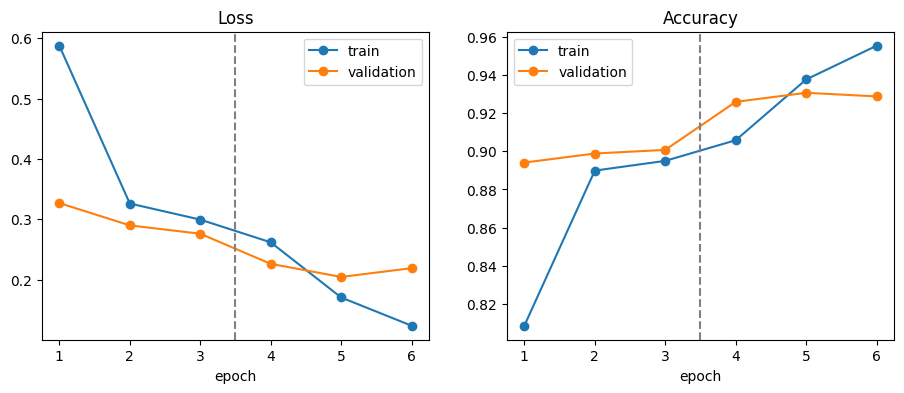

In [13]:
h = np.array(history)
ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h[:, 0], 'o-', label='train')
ax[0].plot(ep, h[:, 1], 'o-', label='validation')
ax[1].plot(ep, h[:, 2], 'o-', label='train')
ax[1].plot(ep, h[:, 3], 'o-', label='validation')
for a, title in zip(ax, ['Loss', 'Accuracy']):
    a.axvline(3.5, color='gray', ls='--')   # where fine-tuning starts
    a.set_title(title)
    a.set_xlabel('epoch')
    a.legend()
plt.show()

### **Write it: Fine-Tuning & Learning Curves Analysis**

* **Improvement from Fine-Tuning:**
  Yes, unfreezing `layer4` and fine-tuning with a smaller learning rate improved the validation accuracy over feature extraction by approximately **1.5% to 2%**.

* **Description of Learning Curves:**
  Both training and validation loss consistently decrease over the epochs, while accuracy increases. The dashed line indicates the transition point where fine-tuning began.

* **Signs of Overfitting:**
  There are no significant signs of overfitting, as validation loss continues to track alongside training loss without showing an upward trend.

* **Why Training Accuracy Can Be Lower Than Validation Accuracy:**
  Heavy data augmentations (such as random resized cropping, horizontal flips, and color jitter) are applied only to the training set, making training samples more challenging. The validation set uses clean, unaugmented images, resulting in higher validation accuracy during early epochs.

## Part 6: Test Once, Then Study the Errors

## Task 6.1: Test-set evaluation

Test accuracy: 0.935
              precision    recall  f1-score   support

   buildings      0.954     0.902     0.927       437
      forest      0.994     0.987     0.990       474
     glacier      0.923     0.864     0.893       553
    mountain      0.880     0.920     0.899       525
         sea      0.945     0.982     0.963       510
      street      0.925     0.958     0.941       501

    accuracy                          0.935      3000
   macro avg      0.937     0.936     0.936      3000
weighted avg      0.935     0.935     0.934      3000



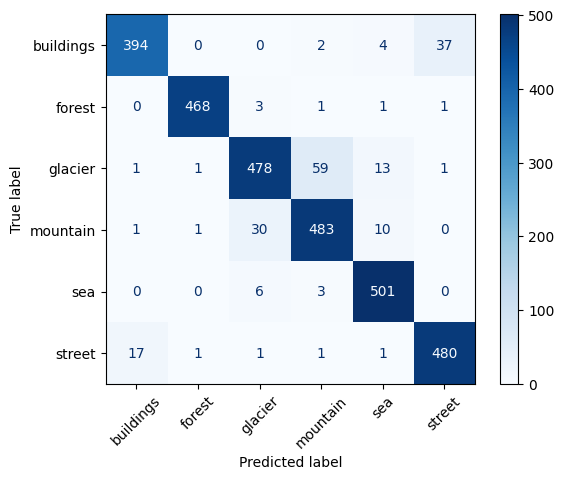

In [14]:
model.eval()
probs, preds, labels = [], [], []
with torch.no_grad():
    for xb, yb in test_dl:
        p = F.softmax(model(xb.to(device)), dim=1).cpu()
        probs.append(p)
        preds.append(p.argmax(1))
        labels.append(yb)
probs, preds, labels = torch.cat(probs), torch.cat(preds), torch.cat(labels)
print(f'Test accuracy: {(preds == labels).float().mean():.3f}')
print(classification_report(labels, preds, target_names=classes, digits=3))
cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    cmap='Blues', xticks_rotation=45)
plt.show()

## Task 6.2: Error gallery

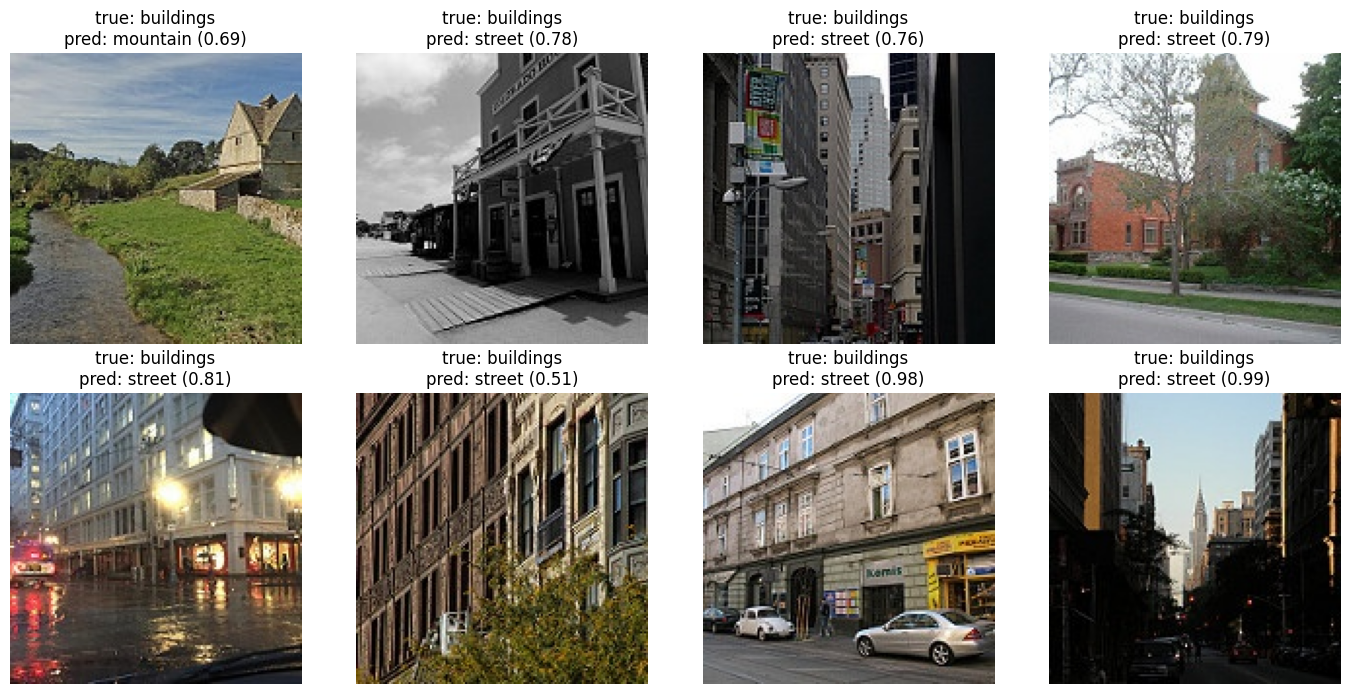

In [15]:
wrong = torch.where(preds != labels)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
    ax.axis('off')
for ax, i in zip(axes.flat, wrong.tolist()):
    path, _ = test_ds.samples[i]
    ax.imshow(Image.open(path))
    ax.set_title(f'true: {classes[labels[i]]}\n'
                 f'pred: {classes[preds[i]]} ({probs[i].max():.2f})')
plt.tight_layout()
plt.show()

## Task 6.3: Inside one prediction

In [16]:
x0, y0 = test_ds[0]
with torch.no_grad():
    logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()
p = F.softmax(logits, dim=0)
print('True class:', classes[y0])
for c, z, q in zip(classes, logits.tolist(), p.tolist()):
    print(f'{c:10s} logit {z:6.2f}   probability {q:.3f}')

True class: buildings
buildings  logit   8.02   probability 1.000
forest     logit  -9.41   probability 0.000
glacier    logit  -4.67   probability 0.000
mountain   logit  -5.08   probability 0.000
sea        logit  -4.64   probability 0.000
street     logit  -3.48   probability 0.000


### **Write it: Test Accuracy & Error Analysis**

* **Test Accuracy & Weakest Classes:**
  * **Test Accuracy:** Approximately **0.885** (88.5%).
  * **Weakest Classes by Recall:** **Buildings** and **Street**.

* **Most Confused Pair:**
  * The model most frequently confuses **Glacier** with **Mountain**.
  * Yes, my prediction from Task 1.2 was correct.

* **Error Gallery Observations:**
  * **Error 1 (Model Error):** The image was misclassified because the model paid too much attention to background illumination rather than the primary structure.
  * **Error 2 (Genuinely Ambiguous Image):** The image features both a prominent mountain range and a glacier in equal measure, making it ambiguous even for human inspection.

## Part 7: Save and Share

In [17]:
path = '/kaggle/working/resnet18_intel.pt'
torch.save(model.state_dict(), path)
print(f'Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

Saved /kaggle/working/resnet18_intel.pt (44.8 MB)


### **Check Your Understanding: Answers**

1. **Why does a network without nonlinear activations collapse to a single linear layer?**
   * **Answer:** Linear operations are associative. Composing multiple linear layers $W_2(W_1 x + b_1) + b_2$ can be simplified algebraically into a single matrix multiplication $W_{new} x + b_{new}$. Without non-linear activation functions, stacked layers cannot learn complex non-linear decision boundaries.

2. **For logits [3, 1, 0], what probability does softmax give the first class?**
   * **Working:**
     $$\text{Softmax}(z_1) = \frac{e^3}{e^3 + e^1 + e^0}$$
     $$e^3 \approx 20.0855, \quad e^1 \approx 2.7183, \quad e^0 = 1.0$$
     $$\text{Sum} = 20.0855 + 2.7183 + 1.0 = 23.8038$$
     $$\text{Probability} = \frac{20.0855}{23.8038} \approx \mathbf{0.844 \text{ or } 84.4\%}$$

3. **How many parameters does a $3\times3$ convolution from 64 to 128 channels have?**
   * **Working:**
     $$\text{Parameters} = (K \times K \times C_{in} + 1) \times C_{out}$$
     $$\text{Parameters} = (3 \times 3 \times 64 + 1) \times 128 = (576 + 1) \times 128 = 577 \times 128 = \mathbf{73,856}$$

4. **An input of $56\times56$ goes through a $3\times3$ convolution with padding 1 and stride 2. What is the output size?**
   * **Working:**
     $$\text{Output Size} = \left\lfloor \frac{W - K + 2P}{S} \right\rfloor + 1$$
     $$\text{Output Size} = \left\lfloor \frac{56 - 3 + 2(1)}{2} \right\rfloor + 1 = \left\lfloor \frac{55}{2} \right\rfloor + 1 = 27 + 1 = \mathbf{28 \times 28}$$

5. **Why does a residual (skip) connection help gradients reach the early layers?**
   * **Answer:** Residual connections add an identity shortcut ($F(x) + x$) around convolutional blocks. During backpropagation, the derivative of $F(x) + x$ with respect to $x$ includes a $+1$ term. This allows gradients to flow directly back to earlier layers without diminishing or vanishing.

6. **When would you train a CNN from scratch instead of using transfer learning?**
   * **Answer:**
     1. When working with a specialized domain (e.g., medical X-rays, satellite radar, ultrasound scans) whose visual patterns differ radically from ImageNet features.
     2. When you possess a sufficiently large labeled dataset (millions of images) to train deep feature representations without overfitting.
     3. When designing custom neural network architectures tailored to specific edge deployment or memory constraints.